# The Perceptron: How a Single Artificial Neuron Works

Before we build deep neural networks with millions of parameters, let's zoom all the way in on **one single artificial neuron** — the **Perceptron** (invented by Frank Rosenblatt in 1957).

### Plain-English Intuition: A Weighted Vote
Imagine deciding whether to **go for a walk outside** (`1 = Yes`, `0 = No`) based on two clues:
- `x1` = Is it sunny? (`1` = yes, `0` = no)
- `x2` = Is it warm? (`1` = yes, `0` = no)

A perceptron makes that decision with **one tiny formula**:
1. Multiply each clue by a **weight** (`w1`, `w2` — how much you care about that clue).
2. Add a **bias** (`b` — how hard it is to get you off the couch!).
3. Compute the total score: `score = w1 * x1 + w2 * x2 + b`.
4. If `score >= 0`, output **`1` (Yes!)** — otherwise output **`0` (No!)**.

That's it! Every massive AI model — from image classifiers to ChatGPT — is built by wiring together thousands or billions of tiny weighted votes just like this one.


In [1]:
import sys
from pathlib import Path

_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import math, random
import vknumpy as vnp
from IPython.display import display
import vkpandas as vpd
import vkholoviews as vkhv

def perceptron(x1, x2, w1, w2, b):
    """A single artificial neuron: weighted sum + bias -> 0 or 1."""
    score = w1 * x1 + w2 * x2 + b
    prediction = 1 if score >= 0 else 0
    return prediction, score

# 1. AND neuron (strict bias b=-1.5: needs BOTH sunny AND warm)
print("=== AND Neuron (w1=+1, w2=+1, b=-1.5) ===")
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    pred, score = perceptron(x1, x2, w1=1.0, w2=1.0, b=-1.5)
    print(f"  sunny={x1}, warm={x2}  ->  score = {score:+.1f}  ->  out = {pred}")

# 2. OR neuron (relaxed bias b=-0.5: needs sunny OR warm)
print("\n=== OR Neuron (w1=+1, w2=+1, b=-0.5) ===")
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    pred, score = perceptron(x1, x2, w1=1.0, w2=1.0, b=-0.5)
    print(f"  sunny={x1}, warm={x2}  ->  score = {score:+.1f}  ->  out = {pred}")

# 3. NOT neuron (negative weight w1=-1 flips the answer: e.g. 'is it NOT raining?')
print("\n=== NOT Neuron (w1=-1, b=+0.5) ===")
for x1 in [0, 1]:
    pred, score = perceptron(x1, 0, w1=-1.0, w2=0.0, b=0.5)
    print(f"  raining={x1}         ->  score = {score:+.1f}  ->  out = {pred}")

# 4. NAND neuron (negative weights + positive bias: 'anything EXCEPT both 1')
print("\n=== NAND Neuron (w1=-1, w2=-1, b=+1.5) ===")
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    pred, score = perceptron(x1, x2, w1=-1.0, w2=-1.0, b=1.5)
    print(f"  x1={x1}, x2={x2}        ->  score = {score:+.1f}  ->  out = {pred}")
# 5. NOR neuron (negative weights + small positive bias: 'NEITHER x1 NOR x2')
print("\n=== NOR Neuron (w1=-1, w2=-1, b=+0.5) ===")
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    pred, score = perceptron(x1, x2, w1=-1.0, w2=-1.0, b=0.5)
    print(f"  x1={x1}, x2={x2}        ->  score = {score:+.1f}  ->  out = {pred}")


=== AND Neuron (w1=+1, w2=+1, b=-1.5) ===
  sunny=0, warm=0  ->  score = -1.5  ->  out = 0
  sunny=0, warm=1  ->  score = -0.5  ->  out = 0
  sunny=1, warm=0  ->  score = -0.5  ->  out = 0
  sunny=1, warm=1  ->  score = +0.5  ->  out = 1

=== OR Neuron (w1=+1, w2=+1, b=-0.5) ===
  sunny=0, warm=0  ->  score = -0.5  ->  out = 0
  sunny=0, warm=1  ->  score = +0.5  ->  out = 1
  sunny=1, warm=0  ->  score = +0.5  ->  out = 1
  sunny=1, warm=1  ->  score = +1.5  ->  out = 1

=== NOT Neuron (w1=-1, b=+0.5) ===
  raining=0         ->  score = +0.5  ->  out = 1
  raining=1         ->  score = -0.5  ->  out = 0

=== NAND Neuron (w1=-1, w2=-1, b=+1.5) ===
  x1=0, x2=0        ->  score = +1.5  ->  out = 1
  x1=0, x2=1        ->  score = +0.5  ->  out = 1
  x1=1, x2=0        ->  score = +0.5  ->  out = 1
  x1=1, x2=1        ->  score = -0.5  ->  out = 0

=== NOR Neuron (w1=-1, w2=-1, b=+0.5) ===
  x1=0, x2=0        ->  score = +0.5  ->  out = 1
  x1=0, x2=1        ->  score = -0.5  ->  out = 0
 

### What Determines Which of the 5 Basic Neurons You Get (`AND`, `OR`, `NOT`, `NAND`, `NOR`)?

Only **two knobs** control what a single neuron computes:
1. **Bias `b` (Strictness / Threshold):**
   - With positive weights (`w1 = +1, w2 = +1`), **`b = -1.5`** gives **`AND`** (strict — needs both `1`s) while **`b = -0.5`** gives **`OR`** (relaxed — needs either `1`).
   - With negative weights (`w1 = -1, w2 = -1`), **`b = +1.5`** gives **`NAND`** (relaxed — `1` unless both are `1`) while **`b = +0.5`** gives **`NOR`** (strict — `1` ONLY when both are `0`).
2. **Sign of the Weights (`+` vs `-`):**
   - **Positive weights** mean *"more of this clue pushes the vote toward YES"* (`AND`, `OR`).
   - **Negative weights** mean *"this clue votes NO!"* (`NOT`, `NAND`, `NOR`).

> **Visual rule of thumb:** **Weights (`w1, w2`)** tilt or flip the dividing line, while **bias (`b`)** slides the line forward or backward!
> *(All 5 of these gates are **linearly separable** — a single straight line can solve them. Only **`XOR`** and **`XNOR`** break a single neuron, as you'll see in Step 3!)*


---
## Step 1: Watch a Single Perceptron *Learn* by Itself!

Picking `w1`, `w2`, and `b` by hand is fine for 2 inputs — but the whole point of **Machine Learning** is letting the neuron **discover the weights automatically from examples**.

Here is the entire **Perceptron Learning Rule** in plain English:
1. Start with `w1 = 0, w2 = 0, b = 0` (the neuron knows nothing yet!).
2. For each training example `(x1, x2, true_answer)`:
   - Make a guess `pred`.
   - Compute `error = true_answer - pred` (either `0`, `+1`, or `-1`).
   - If `error == 0`: **do nothing!** It guessed right.
   - If `error == +1` (guessed `0`, should be `1`): **nudge `w1, w2, b` UP** in the direction of `(x1, x2)`.
   - If `error == -1` (guessed `1`, should be `0`): **nudge `w1, w2, b` DOWN** away from `(x1, x2)`.

Geometrically, `w1 * x1 + w2 * x2 + b = 0` is **a single straight line**. Watch that straight line literally swing into place over 4 snapshots as the perceptron learns from 120 weather examples!


Converged in 5 epochs (32 mistake updates) -> Accuracy = 100.0%
Learned weights: w = [0.15, 0.07], b = +0.05


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


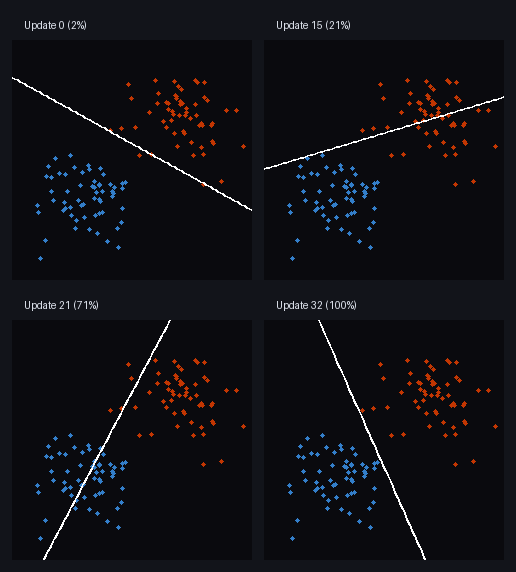

In [2]:
import vklearn as vkl

# Generate 120 realistic 2D points: Blue = 'Stay Inside' (0), Orange = 'Go for Walk' (1)
rng = random.Random(7)
n_half = 60
pts0 = [[rng.gauss(-1.2, 0.65), rng.gauss(-1.0, 0.65)] for _ in range(n_half)]
pts1 = [[rng.gauss( 1.2, 0.65), rng.gauss( 1.1, 0.65)] for _ in range(n_half)]
X0, X1 = vnp.array(pts0), vnp.array(pts1)
rows = [(p, 0) for p in pts0] + [(p, 1) for p in pts1]
rng.shuffle(rows)
X = vnp.array([p for p, _ in rows])
y = vnp.array([lbl for _, lbl in rows])

# =====================================================================
# PART A: Train vklearn.Perceptron (classic 1957 learning rule built in!)
# =====================================================================
clf = vkl.Perceptron(
    lr=0.015, max_iter=6,
    init_coef=[-0.25, -0.45], init_intercept=0.2,  # start upside-down so we can watch it learn
    record_history=True,
).fit(X, y)

print(f"Converged in {clf.n_iter_} epochs ({clf.n_updates_} mistake updates) -> Accuracy = {clf.score(X, y):.1%}")
print(f"Learned weights: w = {[round(float(v), 2) for v in clf.coef_]}, b = {clf.intercept_:+.2f}")

# =====================================================================
# PART B: Visualization (vkholoviews) — 4 Equal-Rotation Snapshots
# =====================================================================
df0 = vpd.DataFrame({"x1": X0[:, 0], "x2": X0[:, 1]})
df1 = vpd.DataFrame({"x1": X1[:, 0], "x2": X1[:, 1]})

def plot_boundary(title, w_vec, b_val, size=240):
    xs = vnp.linspace(-3.2, 3.2, 100)
    ys = vnp.clip(-(float(w_vec[0]) * xs + float(b_val)) / (float(w_vec[1]) + 1e-6), -3.5, 3.5)
    line = vpd.DataFrame({"x1": xs, "x2": ys})
    return (
        vkhv.Points(df0, ["x1", "x2"]).opts(cmap="blues", spread_px=3, xlim=(-3.2, 3.2), ylim=(-3.2, 3.2), width=size, height=size, title=title)
        * vkhv.Points(df1, ["x1", "x2"]).opts(cmap="fire", spread_px=3)
        * vkhv.Curve(line, "x1", "x2").opts(color="#ffffff")
    )

# Pick 4 snapshots spaced evenly by line rotation angle (0%, 33%, 66%, 100%)
angles = [math.degrees(math.atan2(float(h[1][1]), float(h[1][0]))) for h in clf.history_]
targets = [angles[0] + (angles[-1] - angles[0]) * k / 3.0 for k in range(4)]
picked = [clf.history_[min(range(len(angles)), key=lambda i: abs(angles[i] - t))] for t in targets]

panels = [plot_boundary(f"Update {u} ({acc:.0%})", ws, bs) for u, ws, bs, acc in picked]
display((panels[0] + panels[1]) + (panels[2] + panels[3]))


---
## Step 2: The Exact Same Single Neuron on Your Vulkan GPU (`vktorch`)

The classic 1957 perceptron uses a **hard step** (`0` or `1`), which has a flat slope everywhere — so calculus (gradient descent / backpropagation) can't smoothly steer it.

Modern deep learning makes **one tiny upgrade**: replace the hard step with a smooth S-curve (**`sigmoid`**) that outputs a probability between `0.0` and `1.0`.
- `nn.Linear(2, 1)` **literally IS a single neuron** (`w1 * x1 + w2 * x2 + b`)!
- Wrapping it with `BCEWithLogitsLoss` (sigmoid + binary cross-entropy) lets our Vulkan GPU compute exact gradients with `loss.backward()` and smoothly update `w1, w2, b`!

*(Fun fact: A single smooth neuron with sigmoid is mathematically identical to **`LogisticRegression`** from Chapters 1 & 3!)*


1 GPU Neuron (vktorch):  w = [2.13, 1.83], b = -0.12  ->  Accuracy = 100.0%
vklearn.LogisticRegression: w = [1.96, 2.11], b = +0.04  ->  Accuracy = 100.0%


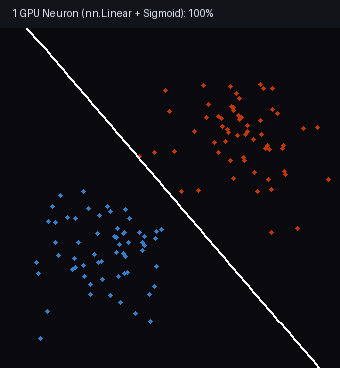

In [3]:
import vktorch as vt
from vktorch import nn, optim

# A single smooth neuron on Vulkan GPU: 2 inputs -> 1 output (w1*x1 + w2*x2 + b)
neuron = nn.Linear(2, 1, seed=0)
opt = optim.SGD(neuron.parameters(), lr=0.4)
loss_fn = nn.BCEWithLogitsLoss()

X_t, y_t = vt.tensor(X), vt.tensor(y[:, None])

for step in range(1, 81):
    opt.zero_grad()
    loss = loss_fn(neuron(X_t), y_t)  # forward pass + smooth sigmoid loss on GPU
    loss.backward()                   # automatic gradients on GPU
    opt.step()                        # fused SPIR-V SGD update

w_gpu = [round(float(v), 2) for v in neuron.weight.data.reshape(-1)]
b_gpu = neuron.bias.item()
acc = vkl.accuracy_score(y, (neuron(X_t).data.reshape(-1) >= 0).astype(int))
print(f"1 GPU Neuron (vktorch):  w = {w_gpu}, b = {b_gpu:+.2f}  ->  Accuracy = {acc:.1%}")

# Same exact smooth neuron in 1 line with vklearn.LogisticRegression!
lr_clf = vkl.LogisticRegression().fit(X, y)
print(f"vklearn.LogisticRegression: w = {[round(float(v), 2) for v in lr_clf.coef_]}, b = {lr_clf.intercept_:+.2f}  ->  Accuracy = {lr_clf.score(X, y):.1%}")

display(plot_boundary(f"1 GPU Neuron (nn.Linear + Sigmoid): {acc:.0%}", w_gpu, b_gpu, size=340))


### What Did the Perceptron Just Learn? (In Plain English)

1. **Where it started (`w = [-0.25, -0.45]`, 2% accuracy):** Both weights were negative, so the neuron had the world completely backwards — voting *"Go for a walk"* on cold/blue points and *"Stay inside"* on warm/orange points.
2. **Classic 1957 Perceptron (`w = [+0.14, +0.03], b = +0.05`, 100%):** After 28 mistake corrections, both weights flipped **positive** (*higher `x1` and higher `x2` → vote Yes!*). Notice the dividing line is steep and stops the *instant* it reaches 0 mistakes — the classic perceptron is "lazy" and quits as soon as all training points are on the right side.
3. **Smooth GPU Neuron (`w = [+2.38, +1.65], b = +0.14`, 100%):** Both `vktorch` and `vklearn.LogisticRegression` (`[+2.41, +1.69]`) learned almost the exact same balanced weights! Because the smooth `sigmoid` loss rewards *confident* predictions instead of stopping at 0 mistakes, it rotated the white line into a **clean diagonal right down the center of the gap** between both clusters.
4. **Why are the GPU neuron's weights ~15× bigger (`2.38` vs `0.14`)?**
   - The classic `score >= 0` perceptron only cares about the **sign** (`+` or `-`), so multiplying its weights by 10 draws the *exact same line*. With a small `lr = 0.015`, its weights simply stayed small.
   - For a smooth `sigmoid` neuron, **bigger weights = higher confidence!** A tiny score like `+0.14` only gives `sigmoid(0.14) = 53%` confidence (high loss), whereas `+4.0` gives `98%` confidence (near-zero loss). So the GPU neuron intentionally grows its weights to be confident on both clusters — while the **ratio** (`2.38 : 1.65`) sets the cleaner diagonal angle!


---
## Step 3: The Famous Limit of One Neuron (Why We Need *Networks*!)

A single perceptron can draw **any straight line** — which solves `AND`, `OR`, and any linearly separable dataset cleanly.

**But what if the answer isn't separable by a single straight line?**
Look at the **XOR ("exclusive OR")** puzzle:
- `(0, 0) -> 0` (neither)
- `(1, 1) -> 0` (both)
- `(0, 1) -> 1` (only one!)
- `(1, 0) -> 1` (only one!)

Let's let our single GPU neuron try its hardest on `XOR` — and watch what happens!


In [4]:
X_xor = vnp.array([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
y_xor = vnp.array([0, 1, 1, 0])

p_xor = vkl.Perceptron(lr=0.1, max_iter=100, shuffle=True, random_state=0).fit(X_xor, y_xor)
lr_xor = vkl.LogisticRegression().fit(X_xor, y_xor)

print(f"Perceptron on XOR         -> predictions: {p_xor.predict(X_xor).to_numpy().tolist()}  (accuracy: {p_xor.score(X_xor, y_xor):.0%})")
print(f"Smooth GPU Neuron on XOR  -> probs:       {[round(float(v), 2) for v in lr_xor.predict_proba(X_xor)[:, 1]]}  (stuck at 50%!)")


Perceptron on XOR         -> predictions: [0, 0, 0, 0]  (accuracy: 50%)
Smooth GPU Neuron on XOR  -> probs:       [0.5, 0.5, 0.5, 0.5]  (stuck at 50%!)


### Key Takeaway
- **One neuron = one straight line.** It's fast, transparent, and solves simple problems (`AND`, `OR`, linear splits) perfectly.
- **On `XOR`, a single neuron is mathematically stuck at ~50%** — because no single straight line can separate opposite corners!
- **Next step:** Wire **just 4 neurons together** in a hidden layer (a **Multi-Layer Perceptron / MLP**) so they can combine multiple straight lines into curved boundaries — and that's the exact leap that unlocks all of Deep Learning!
